# Task 2 - Custom CNN (residual + squeeze-and-excitation)

Recipe from the `custom-complex-cnn` branch (`02_custom_cnn.ipynb`), kept as it was: stride-2 stem, five
residual blocks with squeeze-and-excitation (64, 128, 128, 256, 256 filters, swish), global average pooling,
Dropout(0.4), Dense(128, swish), Dense(4, softmax). Trained from scratch on [0, 1] pixels with
cross-entropy (label smoothing 0.05), Adam 1e-3, batch 32, up to 50 epochs, ReduceLROnPlateau on val_loss
(x0.5, patience 4, min 1e-6), early stopping on val_loss (patience 12), best epoch by val_loss.

**Data.** Same pipeline as every other task (`src/data.py`, the transfer-learning branch protocol): `data/split_aspect.csv` (Kaggle test kept; Kaggle train+val re-split 800/200 per class, stratified by aspect group), square crop from the raw image (random on train, center on val/test) resized to 224x224, train-only affine/flip/brightness/contrast augmentation, and aspect-balanced sampling. Batches arrive as [0, 255] pixels; the model rescales them itself. The best epoch is picked on validation; test is predicted once at the end. The branch itself trained without any augmentation.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))

import keras
import pandas as pd
from keras import layers

import config
from src import data, experiment

experiment.setup()
frames, datasets = data.load_datasets()
{split: len(frame) for split, frame in frames.items()}

I0000 00:00:1791566297.270422   31400 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791566297.307994   31400 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791566298.368515   31400 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | policy: float32


I0000 00:00:1791566299.871353   31400 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3618 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


{'train': 3200, 'val': 800, 'test': 800}

## Model

In [2]:
def se_block(x, ratio=16):
    """Squeeze-and-excitation: learn one weight per channel."""
    channels = x.shape[-1]
    s = layers.GlobalAveragePooling2D()(x)
    s = layers.Dense(channels // ratio, activation="relu", use_bias=False)(s)
    s = layers.Dense(channels, activation="sigmoid", use_bias=False)(s)
    return layers.Multiply()([x, layers.Reshape((1, 1, channels))(s)])


def residual_se_block(x, filters, stride=1):
    shortcut = x
    x = layers.Conv2D(filters, 3, strides=stride, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("swish")(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = se_block(x)
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding="same", use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    return layers.Activation("swish")(layers.Add()([x, shortcut]))


inputs = keras.Input((config.IMAGE_SIZE, config.IMAGE_SIZE, 3))
x = layers.Rescaling(1 / 255)(inputs)
x = layers.Conv2D(32, 3, strides=2, padding="same", use_bias=False)(x)   # 112x112
x = layers.BatchNormalization()(x)
x = layers.Activation("swish")(x)
x = residual_se_block(x, 64)               # 112x112x64
x = residual_se_block(x, 128, stride=2)    # 56x56x128
x = residual_se_block(x, 128)
x = residual_se_block(x, 256, stride=2)    # 28x28x256
x = residual_se_block(x, 256)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="swish")(x)
outputs = layers.Dense(len(config.CLASS_NAMES), activation="softmax")(x)
model = keras.Model(inputs, outputs, name="custom_cnn")

experiment.compile_model(model, keras.optimizers.Adam(1e-3),
                         loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.05))
print(f"{model.count_params():,} parameters")

2,742,628 parameters


## Train and evaluate

In [3]:
fit_info = experiment.fit(model, "custom_cnn", datasets, epochs=50, monitor="val_loss", early_stopping=12,
                          reduce_lr=dict(factor=0.5, patience=4, min_lr=1e-6))

Epoch 1/50


I0000 00:00:1791566301.121844   31400 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


I0000 00:00:1791566309.171354   31472 cuda_dnn.cc:461] Loaded cuDNN version 92000


/home/minhquang/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


100/100 - 63s - 630ms/step - accuracy: 0.6856 - f1: 0.6786 - loss: 0.8958 - val_accuracy: 0.2562 - val_f1: 0.1198 - val_loss: 2.4501 - learning_rate: 0.0010


...

100/100 - 47s - 468ms/step - accuracy: 0.9553 - f1: 0.9524 - loss: 0.3114 - val_accuracy: 0.9450 - val_f1: 0.9451 - val_loss: 0.3344 - learning_rate: 6.2500e-05


Epoch 49/50


100/100 - 49s - 487ms/step - accuracy: 0.9581 - f1: 0.9546 - loss: 0.3065 - val_accuracy: 0.9525 - val_f1: 0.9525 - val_loss: 0.3180 - learning_rate: 6.2500e-05


Epoch 50/50


100/100 - 47s - 468ms/step - accuracy: 0.9494 - f1: 0.9467 - loss: 0.3204 - val_accuracy: 0.9513 - val_f1: 0.9513 - val_loss: 0.3184 - learning_rate: 6.2500e-05


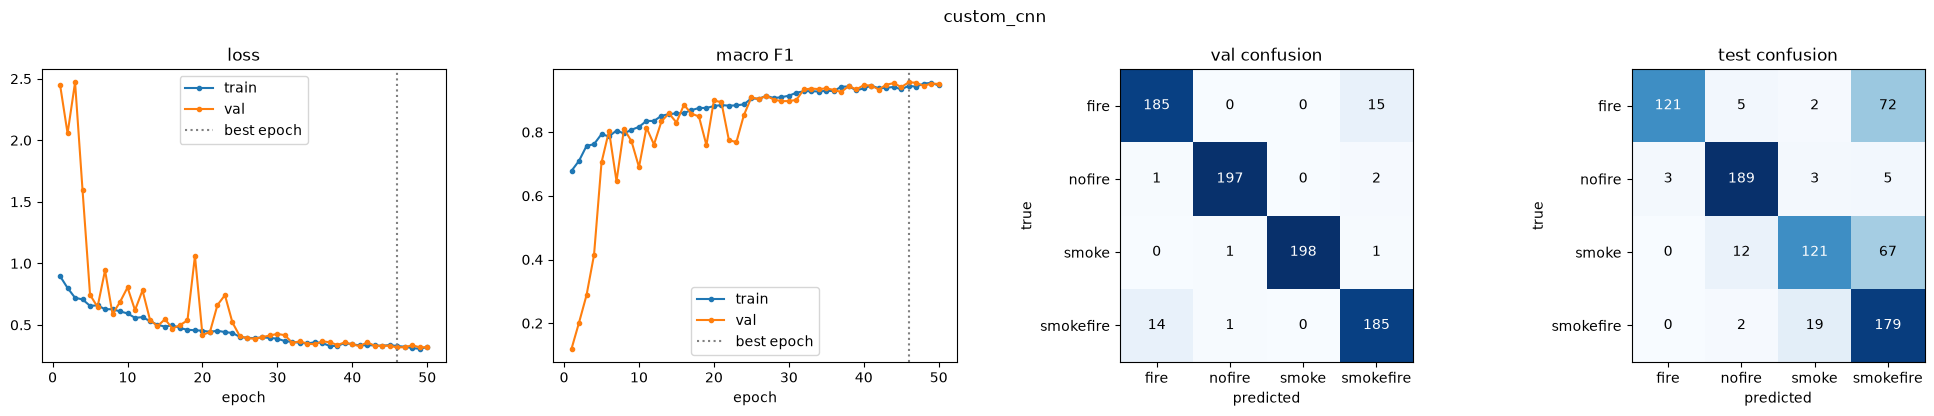

task                                2 custom CNN
run                                   custom_cnn
trainable_params                         2738340
total_params                             2742628
best_epoch                                    46
epochs_run                                    50
train_minutes                               42.6
val_acc                                  0.95625
val_f1                                  0.956389
test_acc                                  0.7625
test_f1                                 0.764836
test_f1_fire                            0.746914
test_f1_nofire                          0.926471
test_f1_smoke                           0.701449
test_f1_smokefire                       0.684512
test_smokefire_as_smoke                       19
test_fire_as_smokefire                        72
test_fire_or_smokefire_as_nofire               7
dtype: object

In [4]:
settings = {"source": "custom-complex-cnn branch, 02_custom_cnn.ipynb", "input": "224, /255",
            "optimizer": "Adam 1e-3", "loss": "categorical cross-entropy, label smoothing 0.05", "epochs": 50,
            "early_stopping": "val_loss, patience 12", "reduce_lr": "val_loss x0.5, patience 4, min 1e-6",
            "selection": "val_loss"}
experiment.evaluate(model, "custom_cnn", "2 custom CNN", frames, datasets, fit_info, settings)

## All runs so far

In [5]:
board = pd.read_csv(config.RESULTS_DIR / "leaderboard.csv")
board[["task", "run", "trainable_params", "best_epoch", "val_acc", "val_f1", "test_acc", "test_f1",
       "test_f1_smokefire", "test_smokefire_as_smoke", "test_fire_as_smokefire"]].round(4)

,task,run,trainable_params,best_epoch,val_acc,val_f1,test_acc,test_f1,test_f1_smokefire,test_smokefire_as_smoke,test_fire_as_smokefire
0,1 basic NN,basic_nn,3147012,28,0.6863,0.6792,0.6050,0.6088,0.4637,107,50
1,2 custom CNN,custom_cnn,2738340,46,0.9563,0.9564,0.7625,0.7648,0.6845,19,72
